# 1. Behavior-IF: phát hiện hành vi bất thường từ bản ghi flow của Suricata

> **Thứ tự chạy: 1.** Chạy notebook này trước. Nó tải dữ liệu về `data/` cho cả hai notebook.

Notebook dựng Behavior-IF: mỗi chiều một tham chiếu Isolation Forest, cửa sổ được chấm cả khi còn mở để cảnh báo sớm (mục 3), đo độ trễ phát hiện (mục 4) và xuất mô hình cho `anomaly.py` (mục 5). Hàm tính toán nằm trong `behavior_features.py`; notebook gọi hàm, in kết quả và xuất mô hình.

In [1]:
%pip install -q numpy==2.5.3 scikit-learn==1.9.1 pandas==3.0.5 scipy joblib matplotlib gdown

Note: you may need to restart the kernel to use updated packages.


## 1. Cấu hình

In [2]:
import os, time
import numpy as np
import pandas as pd
import joblib
import gdown
import sklearn
from scipy.stats import spearmanr
import behavior_features as bf

print("numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)
if (np.__version__, sklearn.__version__) != ("2.5.3", "1.9.1"):
    print("Chú ý: khác phiên bản lúc chốt số liệu (numpy 2.5.3, scikit-learn 1.9.1), cây có thể khác đôi chút.")

SEED, N_TREES = 3, 300      # cỡ mẫu con của từng chiều ở bf.PSI
TRAIN_FRAC = 0.7          # mỗi chiều: 70% luồng đầu để huấn luyện, phần sau để kiểm định
RT_Q_GRID = [0.00002, 0.00005, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.03]   # lưới SCORE_Q
RT_FA_MAX = 3.0          # cảnh báo nhầm mỗi giờ tối đa trên tập kiểm định, mỗi chiều
MODEL_OUT = "net_if_model.joblib"
DATA_DIR = "data"
DRIVE_URL = "https://drive.google.com/drive/folders/1QlMZ7_I7ul-gV1yF_Wk-3d1iKvw4RVLd"   # thư mục dữ liệu trên Google Drive; để trống nếu đã chép dữ liệu vào data/
TEP = ["flow_normal.csv", "flow_test.csv", "flow_runs.csv", "flow_normal_tre.csv.gz", "flow_test_tre.csv.gz"]
TEP_WEB = ["web_get_train.csv", "web_get_test.csv", "web_post_train.csv", "web_post_test.csv"]  # behavior tải cả bộ để web dùng chung
CAN_TAI = TEP + TEP_WEB


def data_path(fn):
    return os.path.join(DATA_DIR, fn)


def chuan_bi_du_lieu():
    """Mỗi lần chạy: kiểm tra data/ đã đủ chưa; thiếu thì tải cả bộ từ Drive, đủ thì bỏ qua. Chỉ notebook này tải."""
    thieu = [f for f in CAN_TAI if not os.path.exists(data_path(f))]
    if not thieu:
        print(f"{DATA_DIR}/ đã đủ {len(CAN_TAI)} tệp, bỏ qua tải.")
        return
    if not DRIVE_URL:
        raise FileNotFoundError(f"Thiếu {len(thieu)} tệp trong {DATA_DIR}/: {thieu}. "
                                "Chép các tệp CSV vào đó hoặc điền DRIVE_URL.")
    print(f"Thiếu {len(thieu)} tệp: {thieu}. Tải từ Drive vào {DATA_DIR}/ ...")
    os.makedirs(DATA_DIR, exist_ok=True)
    gdown.download_folder(url=DRIVE_URL, output=DATA_DIR, quiet=False, resume=True)
    con_thieu = [f for f in CAN_TAI if not os.path.exists(data_path(f))]
    if con_thieu:
        raise FileNotFoundError(f"Tải xong vẫn thiếu: {con_thieu}. "
                                "Kiểm tra quyền truy cập thư mục Drive, hoặc tải tay rồi chép vào data/.")
    print(f"Đã tải đủ {len(CAN_TAI)} tệp vào {DATA_DIR}/.")


chuan_bi_du_lieu()

numpy 2.5.3 | scikit-learn 1.9.1 | pandas 3.0.5
data/ đã đủ 9 tệp, bỏ qua tải.


## 2. Dữ liệu

In [3]:
def ngay(t):
    return pd.Timestamp(t, unit="s", tz="UTC").tz_convert("Asia/Ho_Chi_Minh").strftime("%d/%m %H:%M")


t0 = time.time()
N, A_N = bf.doc_luong(data_path("flow_normal.csv"), bf.COLS, data_path("flow_normal_tre.csv.gz"))
N["_t"] = bf.epoch(N["start"])
CUT = {d: float(np.quantile(N.loc[N["direction"] == d, "_t"], TRAIN_FRAC)) for d in ("out", "in")}
N["part"] = np.where(N["_t"] < N["direction"].map(CUT), "train", "val")

tong = N.groupby(["direction", "part"]).agg(luong=("src", "size"), tu=("_t", "min"), den=("_t", "max"))
tong["tu"] = tong["tu"].map(ngay)
tong["den"] = tong["den"].map(ngay)
print(tong.to_string())
print(f"Đọc trong {time.time() - t0:.0f}s")

RAR = bf.svc_keys(N[N["part"] == "train"]).value_counts()
RAR_COUNTS, RAR_TOTAL = RAR.to_dict(), int(RAR.sum())
print(f"Bảng độ hiếm: {len(RAR_COUNTS)} khóa dịch vụ trên {RAR_TOTAL:,} luồng huấn luyện")
print((RAR / RAR_TOTAL * 100).round(3).head(8).to_string())

                   luong           tu          den
direction part                                    
in        train    77090  12/10 14:07  19/10 06:35
          val      33039  19/10 06:35  25/10 23:58
out       train  2232084  15/09 00:00  27/09 16:26
          val     956608  27/09 16:26  10/10 22:56
Đọc trong 21s


Bảng độ hiếm: 19 khóa dịch vụ trên 2,309,174 luồng huấn luyện
out|ext|TCP|443      86.107
out|ext|UDP|443       7.810
in|ext|TCP|80         3.338
out|ext|TCP|80        0.925
out|ext|UDP|3478      0.887
out|ext|UDP|19302     0.877
out|ext|TCP|4545      0.026
out|ext|TCP|3478      0.012


In [4]:
t0 = time.time()
X, A_X = bf.doc_luong(data_path("flow_test.csv"), bf.COLS + ["label", "run_id", "source"],
                      data_path("flow_test_tre.csv.gz"))
RUNS = pd.read_csv(data_path("flow_runs.csv"), keep_default_na=False)

X = X[X["source"] == "lab"].drop(columns="source")          # kiểm thử trên phần lab
RUNS = RUNS[RUNS["source"] == "lab"].reset_index(drop=True)
# Hai loại lượt giao tiếp định kỳ (beacon) của bộ dữ liệu nằm ngoài phạm vi: bỏ các lượt này cùng luồng của chúng
BO = ["beacon_even", "beacon_irregular"]
bo_id = set(RUNS.loc[RUNS["behavior"].isin(BO), "run_id"])
X = X[~X["run_id"].isin(bo_id)]
RUNS = RUNS[~RUNS["behavior"].isin(BO)].reset_index(drop=True)
print(X.groupby(["direction", "label"]).size().to_string())
X = X[X["label"] != "unknown"]
X["_t"] = bf.epoch(X["start"])
T_DAU = X[X["run_id"] != ""].groupby("run_id")["_t"].min()
GIO_THAT = bf.gio_that(A_N, A_X)
tre = np.r_[N["_toi"] - bf.epoch(N["end"]), X["_toi"] - bf.epoch(X["end"])]
print(f"{len(N):,} luồng huấn luyện và kiểm định, {len(X):,} luồng kiểm thử lab | thời điểm tới trừ lúc kết thúc: "
      f"trung vị {np.median(tre):.1f} s, 90% không quá {np.quantile(tre, .9):.1f} s, lớn nhất {tre.max():.1f} s | "
      f"{time.time() - t0:.0f}s")

direction  label  
in         attack     1298476
           normal       22037
out        attack      117752
           normal      952325
           unknown         20


3,298,821 luồng huấn luyện và kiểm định, 2,390,590 luồng kiểm thử lab | thời điểm tới trừ lúc kết thúc: trung vị 23.3 s, 90% không quá 59.7 s, lớn nhất 605.1 s | 31s


## 3. Huấn luyện và đánh giá

Behavior-IF theo dõi hành vi lộ ra trong thời gian ngắn: dò quét, dò đăng nhập, làm ngập và lượt truyền tệp có tổng dung lượng lớn. Mô hình gom luồng của mỗi cặp máy theo cửa sổ 30 giây trượt 15 giây, chấm lại mỗi 10 giây trên những luồng engine đã nhận và báo ngay lần đầu điểm vượt ngưỡng; cửa sổ chốt khi đồng hồ live đã qua cuối cửa sổ 75 giây. Mỗi chiều có một tham chiếu riêng (`bf.CUA_SO`, `bf.FEATS_RT`, `bf.PSI`):

- **Chiều vào** (bên ngoài kết nối vào vùng nạn nhân): rừng học 5 đặc trưng của hành vi dồn dập, mẫu con 1.024.
- **Chiều ra** (máy nạn nhân kết nối ra ngoài hoặc sang vùng quản trị): rừng học 7 đặc trưng, gồm 5 đặc trưng của chiều vào và hai đặc trưng dung lượng `sqrt_mb_out`, `sqrt_mb_in` để thấy lượt tải lên, tải về có tổng dung lượng lớn; mẫu con 65.536.

Cửa sổ ngắn để hai hành vi nối tiếp nhau của cùng một cặp máy rơi vào hai cửa sổ khác nhau, mỗi hành vi nhận cảnh báo và nhãn riêng. Hành vi phải theo dõi qua thời gian dài, như giao tiếp định kỳ của kênh C2, nằm ngoài phạm vi; hai loại lượt beacon của bộ dữ liệu không được dùng.

Engine thấy một luồng ở lúc Suricata ghi bản ghi flow, tức khi luồng hết hạn theo timeout, không phải lúc luồng bắt đầu. Vì vậy mọi lần chấm ở mục này chỉ dùng những luồng có thời điểm tới (lấy từ `flow_normal_tre.csv.gz` và `flow_test_tre.csv.gz`) không muộn hơn lúc chấm. Ngưỡng chọn trên tập kiểm định theo số cảnh báo engine thật sự phát cho người trực (mở sự cố, tăng mức độ, hành vi đổi dạng): SCORE_Q lớn nhất có không quá 3 cảnh báo nhầm mỗi giờ cho mỗi chiều.

### 3.1 Huấn luyện

In [5]:
t0 = time.time()
W1 = {}
for d in ("out", "in"):
    m = ((N["direction"] == d) & (N["part"] == "train")).to_numpy()
    W1[d] = bf.windows_nhanh(N[m], RAR_COUNTS, RAR_TOTAL, *bf.CUA_SO[d], arrival=N["_toi"].to_numpy()[m], delay_s=bf.RT_DELAY_S)
REF_RT = {"out": bf.fit_ref(W1["out"][bf.FEATS].values, N_TREES, bf.PSI["out"], SEED, idx=bf.IDX_RT["out"])}
# Tham chiếu chiều vào ghép thêm cùng số cửa sổ chiều ra (cùng độ dài cửa sổ) lấy ngẫu nhiên, vì nền chiều vào chỉ có một dịch vụ
m = ((N["direction"] == "out") & (N["part"] == "train")).to_numpy()
mau = bf.windows_nhanh(N[m], RAR_COUNTS, RAR_TOTAL, *bf.CUA_SO["in"], arrival=N["_toi"].to_numpy()[m],
                       delay_s=bf.RT_DELAY_S).sample(n=len(W1["in"]), random_state=SEED)
REF_RT["in"] = bf.fit_ref(np.vstack([W1["in"][bf.FEATS].values, mau[bf.FEATS].values]), N_TREES, bf.PSI["in"], SEED,
                          idx=bf.IDX_RT["in"])
for d in ("out", "in"):
    print(f"Chiều {'ra' if d == 'out' else 'vào'}: cửa sổ {bf.CUA_SO[d][0] * 60:.0f} giây, {len(W1[d]):,} cửa sổ huấn luyện"
          + (f" + {len(mau):,} cửa sổ chiều ra" if d == "in" else "") + f" | mẫu con {bf.PSI[d]:,} | rừng học {', '.join(bf.FEATS_RT[d])}")
print(f"{time.time() - t0:.0f}s")

Chiều ra: cửa sổ 30 giây, 1,291,533 cửa sổ huấn luyện | mẫu con 65,536 | rừng học log_peak_cpm, log_throughput, log_n_ports, frac_incomplete, svc_rarity, sqrt_mb_out, sqrt_mb_in
Chiều vào: cửa sổ 30 giây, 53,812 cửa sổ huấn luyện + 53,812 cửa sổ chiều ra | mẫu con 1,024 | rừng học log_peak_cpm, log_throughput, log_n_ports, frac_incomplete, svc_rarity
180s


### 3.2 Chọn ngưỡng trên tập kiểm định

In [6]:
t0 = time.time()
Q1, SEL_RT = {}, {}
for d in ("out", "in"):
    Q1[(d, "val")] = bf.cham_quy_dao(bf.quy_dao(N[(N["direction"] == d) & (N["part"] == "val")], RAR_COUNTS, RAR_TOTAL, d), REF_RT[d])
    T, SEL_RT[d], gio = bf.chon_nguong_rt(REF_RT[d], Q1[(d, "val")], RT_Q_GRID, RT_FA_MAX)
    assert SEL_RT[d] is not None, f"Chiều {d}: không SCORE_Q nào đạt {RT_FA_MAX} cảnh báo nhầm/giờ"
    print(f"\nChiều {'ra' if d == 'out' else 'vào'}: {len(Q1[(d, 'val')]['base']):,} cửa sổ kiểm định trong {gio:.0f} giờ")
    print(T.to_string(index=False))
    print(f">> SCORE_Q = {SEL_RT[d]['q']} | ngưỡng scikit-learn {SEL_RT[d]['thr_sk']:.6f} | "
          f"{SEL_RT[d]['fa_h']:.2f} cảnh báo nhầm/giờ")
print(f"{time.time() - t0:.0f}s")


Chiều ra: 621,142 cửa sổ kiểm định trong 319 giờ
 SCORE_Q   Ngưỡng  Cửa sổ vượt ngưỡng  Sự cố/giờ  Cảnh báo nhầm/giờ  Tăng mức độ  Đổi dạng
 0.00002 0.772997                  11       0.02               0.02            0         0
 0.00005 0.766590                  25       0.05               0.05            0         0
 0.00010 0.747565                  73       0.14               0.14            0         0
 0.00020 0.720637                 183       0.35               0.35            1         0
 0.00050 0.697458                 409       0.73               0.76           10         0
 0.00100 0.666390                 991       1.49               1.59           18        13
 0.00200 0.638780                1901       2.78               2.93           28        20
 0.00500 0.597940                3897       5.45               5.76           60        40
 0.01000 0.542000                8323      11.44              12.54          203       145
 0.02000 0.501584               16373   


Chiều vào: 26,334 cửa sổ kiểm định trong 161 giờ
 SCORE_Q   Ngưỡng  Cửa sổ vượt ngưỡng  Sự cố/giờ  Cảnh báo nhầm/giờ  Tăng mức độ  Đổi dạng
 0.00002 0.793350                   0        0.0                0.0            0         0
 0.00005 0.780914                   0        0.0                0.0            0         0
 0.00010 0.776763                   0        0.0                0.0            0         0
 0.00020 0.771577                   0        0.0                0.0            0         0
 0.00050 0.759145                   0        0.0                0.0            0         0
 0.00100 0.741867                   0        0.0                0.0            0         0
 0.00200 0.714165                   0        0.0                0.0            0         0
 0.00500 0.692566                   0        0.0                0.0            0         0
 0.01000 0.652792                   0        0.0                0.0            0         0
 0.02000 0.623933                   0   

### 3.3 Kiểm thử

Báo nhầm đo trên lưu lượng nền của giai đoạn kiểm thử. Ở chiều vào, lượt tấn công được chấm ngay trong dòng lưu lượng chung. Ở chiều ra, mỗi lượt được chấm riêng trên các luồng của chính nó, vì các lượt liên tiếp của lab tới cùng một máy đích có thể rơi vào chung một cửa sổ và làm lượt sau được phát hiện nhờ luồng của lượt trước.

Hai hình sau ô kết quả tóm tắt phần kiểm thử: recall theo hành vi, tính theo cửa sổ (cửa sổ của lượt có lần chấm vượt ngưỡng) và theo lượt (lượt có cảnh báo), và phân bố điểm lớn nhất của từng cửa sổ chiều ra qua các lần chấm.

In [7]:
t0 = time.time()
THR = {d: SEL_RT[d]["thr_sk"] for d in ("out", "in")}
ra = X["direction"] == "out"
QT = {"out": bf.quy_dao(X[ra & (X["run_id"] == "")], RAR_COUNTS, RAR_TOTAL, "out"),
      "in": bf.quy_dao(X[~ra], RAR_COUNTS, RAR_TOTAL, "in")}
QA = bf.cham_quy_dao(bf.quy_dao(X[ra & (X["run_id"] != "")], RAR_COUNTS, RAR_TOTAL, "out", tach_luot=True), REF_RT["out"])
NEN = {}
for d in ("out", "in"):
    bf.cham_quy_dao(QT[d], REF_RT[d])
    c = NEN[d] = bf.chi_so_nen(QT[d], THR[d])
    print(f"Chiều {'ra' if d == 'out' else 'vào'}: FPR kiểm thử {c['FPR (%)']}% trên {c['cửa sổ bình thường']:,} cửa sổ bình "
          f"thường ({c['cửa sổ vượt ngưỡng']} cửa sổ vượt ngưỡng), {c['cảnh báo nhầm']} cảnh báo nhầm, "
          f"{c['cảnh báo nhầm/giờ']} mỗi giờ trong {c['giờ']} giờ | {c['giờ có lưu lượng']} giờ có lưu lượng nền: "
          f"{c['cảnh báo nhầm'] / c['giờ có lưu lượng']:.2f} mỗi giờ")
PH = {"out": bf.phat_hien(QA, THR["out"], T_DAU), "in": bf.phat_hien(QT["in"], THR["in"], T_DAU)}
LAT1, N_BAO = pd.concat([PH["out"][0], PH["in"][0]]), pd.concat([PH["out"][1], PH["in"][1]])
print(f"Lượt và phiên được phát hiện: {len(LAT1)}/{len(RUNS)} | {time.time() - t0:.0f}s")

Chiều ra: FPR kiểm thử 0.348% trên 575,145 cửa sổ bình thường (2000 cửa sổ vượt ngưỡng), 1003 cảnh báo nhầm, 1.99 mỗi giờ trong 504.7 giờ | 386 giờ có lưu lượng nền: 2.60 mỗi giờ


Chiều vào: FPR kiểm thử 0.0% trên 17,507 cửa sổ bình thường (0 cửa sổ vượt ngưỡng), 0 cảnh báo nhầm, 0.0 mỗi giờ trong 136.4 giờ | 131 giờ có lưu lượng nền: 0.00 mỗi giờ
Lượt và phiên được phát hiện: 429/429 | 32s


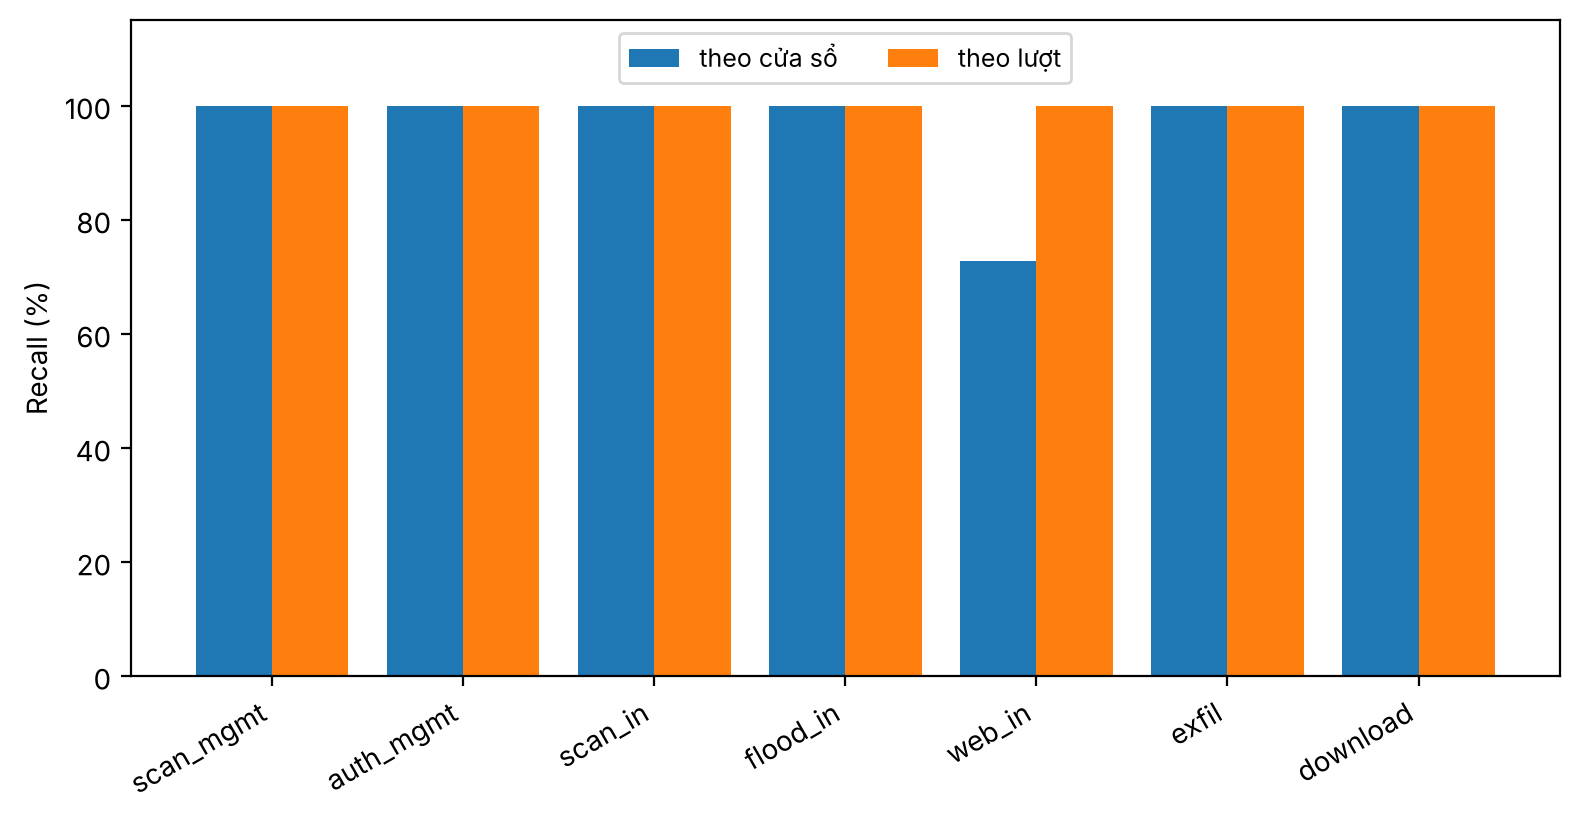

Recall theo cửa sổ (%): scan_mgmt 100,0, auth_mgmt 100,0, scan_in 100,0, flood_in 100,0, web_in 72,7, exfil 100,0, download 100,0
Số cửa sổ: scan_mgmt 234, auth_mgmt 821, scan_in 55, flood_in 232, web_in 88, exfil 981, download 1580 | chung 99,40% trên 3,991 cửa sổ
Theo cửa sổ: TP 3,967, FN 24 | chiều ra FP 2000, TN 573,145 | chiều vào FP 0, TN 17,507 | precision 66,48%


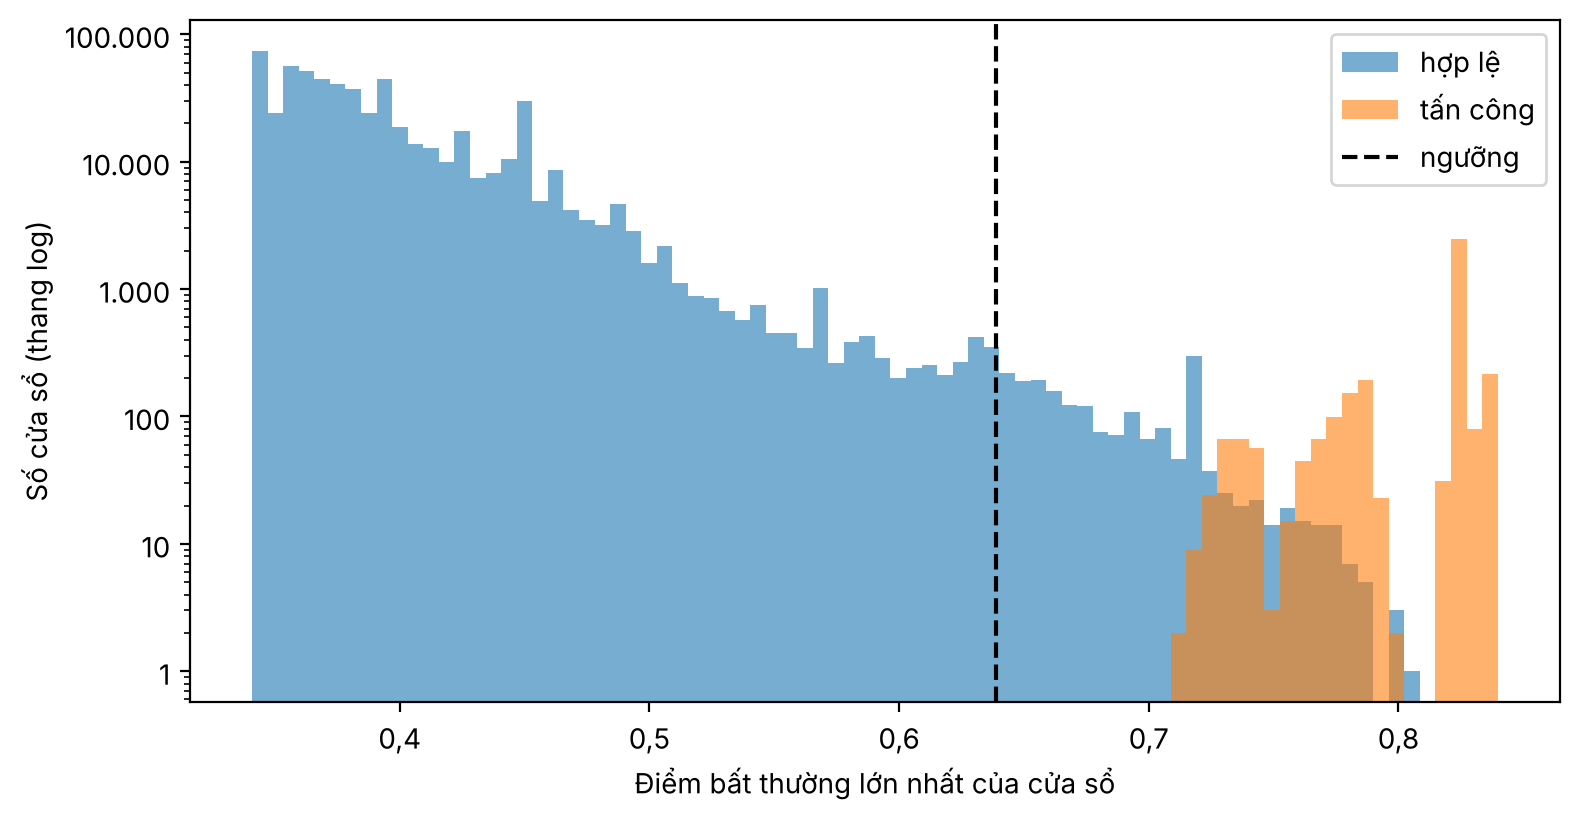

Điểm lớn nhất của cửa sổ chiều ra: hợp lệ 97,3% dưới 0,5 | tấn công trung vị 0,824, tứ phân vị 0,822 đến 0,827
Cửa sổ hợp lệ: 2,000 vượt ngưỡng, điểm lớn nhất 0,807 | cửa sổ tấn công: điểm nhỏ nhất 0,713, 511 cửa sổ hợp lệ có điểm từ mức này trở lên


In [8]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

so = lambda v, n=1: f"{v:.{n}f}".replace(".", ",")      # số thập phân dùng dấu phẩy như trong báo cáo
os.makedirs("docs", exist_ok=True)                      # hình đồng thời được ghi vào docs/ để README dùng
hanh_vi = dict(zip(RUNS["run_id"], RUNS["behavior"]))

# Recall theo hành vi: theo cửa sổ (cửa sổ của lượt có lần chấm vượt ngưỡng) và theo lượt (lượt có cảnh báo)
cua_so = []
for d, Q in (("out", QA), ("in", QT["in"])):
    vuot = np.maximum.reduceat(Q["s"] > THR[d], Q["lo"])
    for r, v in zip(Q["base"]["runs"], vuot):
        cua_so += [(hanh_vi[x], bool(v)) for x in r.split("|") if x]
CS = pd.DataFrame(cua_so, columns=["hv", "vuot"]).groupby("hv")["vuot"].agg(["mean", "size"])
LU = RUNS.assign(bat=RUNS["run_id"].isin(LAT1.index)).groupby("behavior")["bat"].agg(["mean", "size"])
hv = [b for b in bf.HV_THU_TU if b in LU.index]
x = np.arange(len(hv))
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - 0.2, 100 * CS.loc[hv, "mean"], 0.4, label="theo cửa sổ")
ax.bar(x + 0.2, 100 * LU.loc[hv, "mean"], 0.4, label="theo lượt")
ax.set_xticks(x)
ax.set_xticklabels(hv, rotation=30, ha="right")
ax.set_ylim(0, 115)
ax.set_ylabel("Recall (%)")
ax.legend(loc="upper center", ncol=2, fontsize=9)
plt.tight_layout()
fig.savefig("docs/behavior_if_recall.png", dpi=220)
plt.show()
print("Recall theo cửa sổ (%):", ", ".join(f"{b} {so(100 * CS.loc[b, 'mean'])}" for b in hv))
print("Số cửa sổ:", ", ".join(f"{b} {int(CS.loc[b, 'size'])}" for b in hv),
      f"| chung {so(100 * pd.DataFrame(cua_so)[1].mean(), 2)}% trên {len(cua_so):,} cửa sổ")
tp = sum(v for _, v in cua_so)
fp = {d: NEN[d]["cửa sổ vượt ngưỡng"] for d in ("out", "in")}
print(f"Theo cửa sổ: TP {tp:,}, FN {len(cua_so) - tp} | chiều ra FP {fp['out']}, TN {NEN['out']['cửa sổ bình thường'] - fp['out']:,} | "
      f"chiều vào FP {fp['in']}, TN {NEN['in']['cửa sổ bình thường'] - fp['in']:,} | "
      f"precision {so(100 * tp / (tp + fp['out'] + fp['in']), 2)}%")

# Phân bố điểm lớn nhất của từng cửa sổ chiều ra trên tập kiểm thử
lon_nhat = lambda Q: np.maximum.reduceat(Q["s"], Q["lo"])
# Trục dọc là số cửa sổ theo thang log: nhóm hợp lệ đông gấp hàng trăm lần nhóm tấn công, vẽ theo mật độ thì không thấy phần
# đuôi của nhóm hợp lệ, tức phần quyết định vị trí của ngưỡng
hl, tc = lon_nhat(QT["out"]), lon_nhat(QA)
bins = np.linspace(min(hl.min(), tc.min()), max(hl.max(), tc.max()), 81)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(hl, bins=bins, alpha=0.6, label="hợp lệ")
ax.hist(tc, bins=bins, alpha=0.6, label="tấn công")
ax.axvline(THR["out"], color="k", ls="--", label="ngưỡng")
ax.set_yscale("log")
ax.set_xlabel("Điểm bất thường lớn nhất của cửa sổ")
ax.set_ylabel("Số cửa sổ (thang log)")
ax.legend()
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: so(v)))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{int(v):,}".replace(",", ".") if v >= 1 else ""))
plt.tight_layout()
fig.savefig("docs/behavior_if_phan_bo_diem.png", dpi=220)
plt.show()
print(f"Điểm lớn nhất của cửa sổ chiều ra: hợp lệ {so(100 * (hl < 0.5).mean())}% dưới 0,5 | tấn công trung vị {so(np.median(tc), 3)}, "
      f"tứ phân vị {so(np.quantile(tc, .25), 3)} đến {so(np.quantile(tc, .75), 3)}")
print(f"Cửa sổ hợp lệ: {(hl > THR['out']).sum():,} vượt ngưỡng, điểm lớn nhất {so(hl.max(), 3)} | cửa sổ tấn công: điểm nhỏ nhất {so(tc.min(), 3)}, "
      f"{(hl >= tc.min()).sum():,} cửa sổ hợp lệ có điểm từ mức này trở lên")


### 3.4 So sánh bản tự cài và scikit-learn

In [9]:
for d in ("out", "in"):
    V = N[(N["direction"] == d) & (N["part"] == "val")]
    Vw = bf.windows_nhanh(V, RAR_COUNTS, RAR_TOTAL, *bf.CUA_SO[d], arrival=V["_toi"].to_numpy(), delay_s=bf.RT_DELAY_S)[bf.FEATS].values
    idx = np.random.default_rng(SEED).choice(len(Vw), min(5000, len(Vw)), replace=False)
    rho = spearmanr(bf.score(REF_RT[d], Vw[idx]), bf.score(REF_RT[d], Vw[idx], "sk")).correlation
    T1 = X[X["direction"] == d]
    Tw = bf.windows_nhanh(T1, RAR_COUNTS, RAR_TOTAL, *bf.CUA_SO[d], arrival=T1["_toi"].to_numpy(), delay_s=bf.RT_DELAY_S)
    Tw = Tw[Tw["runs"] != ""]
    thr_own = float(np.quantile(REF_RT[d]["s_tr"], 1 - SEL_RT[d]["q"]))
    a = bf.score(REF_RT[d], Tw[bf.FEATS].values) > thr_own
    b = bf.score(REF_RT[d], Tw[bf.FEATS].values, "sk") > SEL_RT[d]["thr_sk"]
    print(f"Chiều {'ra' if d == 'out' else 'vào'}: Spearman (tự cài - scikit-learn) {rho:.4f} trên {len(idx):,} cửa sổ kiểm "
          f"định | ngưỡng tự cài {thr_own:.4f}, scikit-learn {SEL_RT[d]['thr_sk']:.4f} | {len(Tw):,} cửa sổ tấn công ở trạng thái "
          f"chốt: hai bản cùng quyết định {100 * (a == b).mean():.2f}% (tự cài gắn cờ {100 * a.mean():.1f}%, scikit-learn {100 * b.mean():.1f}%)")

Chiều ra: Spearman (tự cài - scikit-learn) 0.9961 trên 5,000 cửa sổ kiểm định | ngưỡng tự cài 0.6383, scikit-learn 0.6388 | 3,616 cửa sổ tấn công ở trạng thái chốt: hai bản cùng quyết định 100.00% (tự cài gắn cờ 100.0%, scikit-learn 100.0%)


Chiều vào: Spearman (tự cài - scikit-learn) 0.8731 trên 5,000 cửa sổ kiểm định | ngưỡng tự cài 0.6118, scikit-learn 0.6153 | 375 cửa sổ tấn công ở trạng thái chốt: hai bản cùng quyết định 98.93% (tự cài gắn cờ 92.5%, scikit-learn 93.6%)


### 3.5 Diễn giải

Đặc trưng lệch nhất ở lần vượt ngưỡng sớm nhất của mỗi lượt, tức đặc trưng đứng đầu phần lý do trên cảnh báo đầu tiên engine phát cho lượt đó, và đặc trưng lệch nhất ở các cửa sổ hợp lệ bị gắn cờ trên tập kiểm thử.

In [10]:
hanh_vi = dict(zip(RUNS["run_id"], RUNS["behavior"]))
ten = lambda k: bf.FEATS[k] if k >= 0 else "-"
dong, nham = [], {}
for d, Q in (("out", QA), ("in", QT["in"])):
    v = np.flatnonzero(Q["s"] > THR[d])
    e = Q["dau"].merge(pd.DataFrame({"r": Q["r"][v], "j": Q["j"][v], "k": Q["k"][v], "ev": v}), on="r")
    e = e[e["j"] >= e["j_dau"]]
    e["t"] = Q["ws"][e["r"].to_numpy()] + Q["taus"][e["j"].to_numpy()]
    dong.append(e.sort_values("t", kind="stable").drop_duplicates("run"))
for d in ("out", "in"):
    Q = QT[d]
    ix = bf.vuot_nguong(Q, THR[d], False)                      # lần vượt ngưỡng đầu tiên của mỗi cửa sổ
    ix = ix[Q["base"]["runs"].to_numpy()[Q["r"][ix]] == ""]
    nham[d] = pd.Series([ten(k) for k in Q["k"][ix]], dtype=object).value_counts()
A = pd.concat(dong, ignore_index=True)
A["Hành vi"] = A["run"].map(hanh_vi)
A["Đặc trưng lệch nhất"] = [ten(k) for k in A["k"]]
print("Đặc trưng lệch nhất ở lần vượt ngưỡng sớm nhất của mỗi lượt (số lượt):")
print(A.groupby(["Hành vi", "Đặc trưng lệch nhất"]).size().to_string())
print("\nCửa sổ hợp lệ bị gắn cờ theo đặc trưng lệch nhất:")
for d, c in nham.items():
    print(f"Chiều {'ra' if d == 'out' else 'vào'}: " + (", ".join(f"{k} {v}" for k, v in c.items()) or "không có"))

print("\nĐiểm và ba đại lượng lệch nhất ở lần vượt ngưỡng sớm nhất, lượt đầu tiên của mỗi hành vi:")
for (d, Q), e in zip((("out", QA), ("in", QT["in"])), dong):
    e = e.assign(hv=e["run"].map(hanh_vi)).sort_values("run").drop_duplicates("hv")
    thang = np.where(REF_RT[d]["scale"] < 1e-9, 1.0, REF_RT[d]["scale"])
    for _, h in e.iterrows():
        z = np.clip((Q["X"][h["ev"]] - REF_RT[d]["med"]) / thang, -50, 50)
        top = [i for i in np.argsort(-np.abs(z), kind="stable")[:3] if abs(z[i]) > 1]
        print(f"  {h['hv']:17s} {h['run']}: điểm {so(Q['s'][h['ev']], 3)} | " + ", ".join(f"{bf.FEATS[i]} ({so(z[i])})" for i in top))


Đặc trưng lệch nhất ở lần vượt ngưỡng sớm nhất của mỗi lượt (số lượt):
Hành vi    Đặc trưng lệch nhất
auth_mgmt  periodicity              1
           svc_rarity             117
download   sqrt_mb_in             101
exfil      sqrt_mb_out             85
flood_in   log_n_conn               1
           svc_rarity               1
           uniformity               1
scan_in    log_n_ports              2
scan_mgmt  log_n_ports            109
web_in     uniformity              11

Cửa sổ hợp lệ bị gắn cờ theo đặc trưng lệch nhất:
Chiều ra: log_n_ports 766, sqrt_mb_in 755, svc_rarity 418, sqrt_mb_out 43, uniformity 6, periodicity 5, log_throughput 4, log_n_conn 3
Chiều vào: không có

Điểm và ba đại lượng lệch nhất ở lần vượt ngưỡng sớm nhất, lượt đầu tiên của mỗi hành vi:
  download          A-001: điểm 0,824 | sqrt_mb_in (50,0), svc_rarity (14,6), sqrt_mb_out (8,2)
  scan_mgmt         A-002: điểm 0,818 | log_n_ports (50,0), svc_rarity (14,6), log_n_conn (4,1)
  exfil             A-009: đi

## 4. Độ trễ phát hiện

Độ trễ tính từ lúc bắt đầu luồng đầu tiên của lượt tới lúc engine nổ, đổi sang giờ thật theo thời điểm Suricata ghi bản ghi; chưa cộng chu kỳ đọc 10 giây của engine. Cột sàn là lúc Suricata ghi bản ghi đầu tiên của lượt, tức sớm nhất mà một bộ phát hiện đọc `eve.json` có thể biết. Cột chấm khi cửa sổ đóng là độ trễ nếu mỗi cửa sổ chỉ được chấm một lần lúc chốt, để so với cách chấm khi cửa sổ còn mở. Độ trễ tính theo bản scikit-learn mà `anomaly.py` dùng.

In [11]:
DONG = pd.concat([bf.tre_khi_dong(QA, THR["out"], T_DAU), bf.tre_khi_dong(QT["in"], THR["in"], T_DAU)])
COT = {"Sàn": X[X["run_id"] != ""].groupby("run_id")["_ghi"].min() - T_DAU,
       "Chấm khi cửa sổ đóng": bf.tre_gio_that(DONG, T_DAU, GIO_THAT),
       "Behavior-IF": bf.tre_gio_that(LAT1, T_DAU, GIO_THAT)}
print("Độ trễ theo giờ thật, tính từ luồng đầu tiên của lượt: số lượt bắt được, trung vị (tối đa)")
print(bf.bang_do_tre(COT, RUNS, N_BAO).to_string(index=False))

Độ trễ theo giờ thật, tính từ luồng đầu tiên của lượt: số lượt bắt được, trung vị (tối đa)
  Hành vi                 Sàn Chấm khi cửa sổ đóng          Behavior-IF Cảnh báo mỗi lượt
scan_mgmt  109/109, 61 s (62) 109/109, 145 s (164)  109/109, 73 s (129)           1 (1-1)
auth_mgmt  118/118, 64 s (70) 118/118, 144 s (174)  118/118, 72 s (107)           1 (1-2)
  scan_in      2/2, 62 s (62)     2/2, 141 s (142)       2/2, 65 s (68)           2 (1-2)
 flood_in        3/3, 3 s (3)     3/3, 418 s (786)        3/3, 6 s (77)           3 (2-4)
   web_in    11/11, 64 s (68)  11/11, 494 s (1951)     11/11, 86 s (95)           1 (1-2)
    exfil  85/85, 103 s (178)   85/85, 147 s (447)   85/85, 114 s (447)           1 (1-1)
 download 101/101, 96 s (132) 101/101, 146 s (165) 101/101, 112 s (152)           1 (1-2)


## 5. Xuất mô hình cho anomaly.py

In [12]:
def goi_rt(d):
    r = REF_RT[d]
    return {"iso": r["sk"], "mu": r["mu"][bf.IDX_RT[d]], "sd": r["sd"][bf.IDX_RT[d]], "med": r["med"], "scale": r["scale"],
            "thr": SEL_RT[d]["thr_sk"], "score_q": SEL_RT[d]["q"], "s_sk": r["s_sk"].astype("float32"),
            "feats": bf.FEATS_RT[d], "feats_all": bf.FEATS, "unit": "pair",
            "window_min": bf.CUA_SO[d][0], "window_hop_min": bf.CUA_SO[d][1], "quiet_s": bf.RT_QUIET_S[d],
            "rescore": bf.CHAM_TIEP[d], "rarity_counts": RAR_COUNTS, "rarity_total": RAR_TOTAL}


M = {"rt": {"out": goi_rt("out"), "inbound": goi_rt("in"), "delay_s": bf.RT_DELAY_S, "interval_s": bf.RT_STEP_S,
            "version": "KLTN 11/2026: Behavior-IF cửa sổ 30 giây cho cả hai chiều, chiều ra 7 đặc trưng, chiều vào 5 đặc trưng"}}
joblib.dump(M, MODEL_OUT, compress=3)
print(f"Đã lưu {MODEL_OUT} ({os.path.getsize(MODEL_OUT) / 1e6:.1f} MB) | ngưỡng scikit-learn: "
      f"chiều ra {M['rt']['out']['thr']:.6f}, chiều vào {M['rt']['inbound']['thr']:.6f}")

Đã lưu net_if_model.joblib (30.0 MB) | ngưỡng scikit-learn: chiều ra 0.638780, chiều vào 0.615255
